# Pore graph (region adjacency graph)

A segmentation gives you pockets and the windows between them. The **pore graph** (also called the region adjacency graph, RAG) turns that into a [networkx](https://networkx.org/) graph: pockets are nodes and windows are edges. This page builds the graph two ways, reads its attributes, and plots it on top of the framework.

It assumes you have seen the [Quick start](quick_start.qmd). Parameter defaults and safe ranges are on [Tuning and safe ranges](parameter_tuning.qmd).

## Structure, grid, and segmentation

In [1]:
#| output: false
import numpy as np
from ase.io import read
import mofography as mgr

atoms = read("../examples/TestCIFs/P1-IRMOF-1.cif")   # docs/ is the working directory
atoms_bonded = mgr.update_with_covalent_bonds(atoms)    # adds bonds for plotting

spacing = 0.5
dgrid = mgr.dgrid_from_atoms_rust(atoms, spacing=spacing).astype(np.float32)

/Users/arungopalan/miniforge3/envs/mgr_env/lib/python3.13/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


[RAYON] current_num_threads = 14


`do_periodic_segmentation_rust` finds the pockets, merges periodic images, and detects the windows in one call. See the [Quick start](quick_start.qmd) for what each key holds.

In [2]:
#| output: false
seg = mgr.do_periodic_segmentation_rust(
    dgrid, atoms, spacing=spacing, return_dgrid=True, disable_tqdm=True,
)
regions = seg["regions_pbc"]
maxima = seg["maxima_pbc"]
pbc_groups = seg["pbc_groups"]

print(len(maxima), "pockets;", len(pbc_groups), "PBC groups")

[RAYON] current_num_threads = 14
/Users/arungopalan/repos/mofography/mofography/helper.py:623: RuntimeWarning: overflow encountered in scalar subtract
  pos_minus[dim] = max(pos_minus[dim] - 1, 0)


[pocket_maxima_check] Region 1: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 3: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 4: pocket_radius from maxima_info (5.284 Å) underestimates true region max (5.629 Å) by 0.345 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 5: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 9: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


... (5 outputs left out)

[pocket_maxima_check] Region 16: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 17: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


[pocket_maxima_check] Region 18: pocket_radius from maxima_info (5.493 Å) underestimates true region max (5.846 Å) by 0.353 Å; this suggests a missing or under-detected maximum.


8 pockets; 8 PBC groups


## Building the graph

There are two ways to build the graph from a segmentation.

| Option | Function | What you get |
|---|---|---|
| 1 | `get_rag_from_regions_and_grid` | The compact graph: one node per PBC-merged pocket (8 for IRMOF-1), built from the regions and the distance grid. Use it when you want one node per pocket for analysis. |
| 2 | `rag_from_connections` | **Go-to builder.** One node per maximum including the periodic images in the padded cell (125 for IRMOF-1), with edges taken directly from the detected windows. It is what the Quick start uses, and it lets you control which windows become edges. |

::: {.callout-note}
Option 1 needs `regions_pbc` and `maxima_pbc` from the same segmentation, with one maximum per region. It fails on the unmerged `regions` array, whose region count does not match the maxima.
:::

### Option 1: from regions and the grid

In [3]:
rag = mgr.get_rag_from_regions_and_grid(regions, dgrid, atoms, maxima)
print(rag.number_of_nodes(), "nodes,", rag.number_of_edges(), "edges")

8 nodes, 12 edges


### Option 2: from the window list

`seg["connections"]` holds the windows. See [Connections and windows](connections_and_windows.qmd) for how they are detected.

In [4]:
rag_c = mgr.rag_from_connections(seg["connections"], seg["all_maxima"])
print(rag_c.number_of_nodes(), "nodes (with periodic images),", rag_c.number_of_edges(), "edges")

125 nodes (with periodic images), 54 edges


## Reading graph attributes

The graph is a standard networkx object, so every networkx function works on it. Nodes and edges:

In [5]:
import networkx as nx

print("nodes:", list(rag.nodes()))
print("edges:", list(rag.edges())[:8], "...")

nodes: [np.int64(8), np.int64(3), np.int64(2), np.int64(1), np.int64(7), np.int64(6), np.int64(5), np.int64(4)]
edges: [(np.int64(8), np.int64(3)), (np.int64(8), np.int64(1)), (np.int64(8), np.int64(5)), (np.int64(3), np.int64(2)), (np.int64(3), np.int64(7)), (np.int64(2), np.int64(1)), (np.int64(2), np.int64(4)), (np.int64(1), np.int64(6))] ...


Turn on `data=True` to get the attributes. Node 0 is reserved for the background, so pockets start at 1:

In [6]:
rag.nodes(data=True)[1]

{'labels': [np.int64(1)],
 'pixel count': 9104,
 'total color': array([18444.41698402, 18444.41698402, 18444.41698402]),
 'mean color': array([2.02596847, 2.02596847, 2.02596847]),
 'centroid': array([12.66761538, 12.66761538, 12.66761538]),
 'centroid_indices': (np.float64(25.5), np.float64(25.5), np.float64(25.5)),
 'maxima': array([ 0.        , 12.41923077, 24.83846154]),
 'maxima_indices': array([ 0, 25, 50]),
 'maxima_radii': np.float32(5.4933887)}

Pull one attribute for every node with `nx.get_node_attributes`. Use `nx.set_node_attributes` to write one. See the [networkx documentation](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.nodes.html); edges work the same way.

In [7]:
nx.get_node_attributes(rag, "maxima")

{np.int64(8): array([25.33523077, 25.33523077,  0.        ]),
 np.int64(3): array([ 0.        , 24.83846154, 12.916     ]),
 np.int64(2): array([ 0.        , 12.916     , 12.41923077]),
 np.int64(1): array([ 0.        , 12.41923077, 24.83846154]),
 np.int64(7): array([12.916     , 25.33523077, 12.41923077]),
 np.int64(6): array([12.916, 12.916,  0.   ]),
 np.int64(5): array([12.41923077,  0.        ,  0.49676923]),
 np.int64(4): array([11.92246154, 12.916     , 12.41923077])}

## Adding properties

Add the periodic-boundary information to the graph. Each node gets a `pbc_group` key naming the group its periodic images belong to:

In [8]:
rag = mgr.add_pbc_to_rag(rag, seg["pbc_groups"])
rag.nodes[1]

{'labels': [np.int64(1)],
 'pixel count': 9104,
 'total color': array([18444.41698402, 18444.41698402, 18444.41698402]),
 'mean color': array([2.02596847, 2.02596847, 2.02596847]),
 'centroid': array([12.66761538, 12.66761538, 12.66761538]),
 'centroid_indices': (np.float64(25.5), np.float64(25.5), np.float64(25.5)),
 'maxima': array([ 0.        , 12.41923077, 24.83846154]),
 'maxima_indices': array([ 0, 25, 50]),
 'maxima_radii': np.float32(5.4933887),
 'pbc_group': np.int64(0)}

Pocket types are added in the same way; see [Pocket type detection](pockets_detection.qmd).

## Visualizing the pore graph

To draw the graph, use `plot_connections_as_it_is`. It plots the detected connections (`seg["connections"]`) and the pockets they join, including the periodic images, so what you see is exactly what the graph was built from. Like every other mofography plotting function it returns traces, so it combines with the framework, cell, surface, and maxima traces. Build those first:


In [9]:
#| output: false
import plotly.express as px
import plotly.graph_objects as go

cscale = px.colors.qualitative.Pastel_r

frame_trace = mgr.plot_framework_as_mesh(atoms_bonded, stylize=True)
cell_trace = mgr.plot_cell(atoms_bonded)
# isovalue is a distance from the framework (Å); keep it well above mask_thickness (0.05)
surface_trace = mgr.plot_surface_dgrid(
    dgrid, isovalue=1.75, ase_atoms=atoms_bonded, opacity=0.7,
    region_labels=regions, cscale=cscale, stylize=True,
)
maxima_trace = mgr.plot_maxima(dgrid, maxima, ase_atoms=atoms_bonded)
connections_traces = mgr.plot_connections_as_it_is(
    seg["connections"], seg["all_maxima"], dgrid.shape, atoms_bonded
)

[TIMING batched_mesh_for_atoms] 472 atoms, 1024 bonds | spheres: 0.00s, cylinders: 0.00s, concat: 0.00s | total faces: 212480


/Users/arungopalan/repos/mofography/mofography/visualize.py:2531: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertices_per_sphere = int(len(vertexcolors[vertexcolors!=bond_rgba_string])/ase_atoms.get_number_of_atoms())
/Users/arungopalan/repos/mofography/mofography/visualize.py:2532: FutureWarning: Please use len(self) or, if your atoms are distributed, self.get_global_number_of_atoms.
  vertex_atom_ids = np.repeat(np.arange(ase_atoms.get_number_of_atoms()), vertices_per_sphere)


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]


Combine them into one figure. `renderer="png"` keeps this page light; use `renderer="notebook_connected"` in Jupyter for an interactive view.

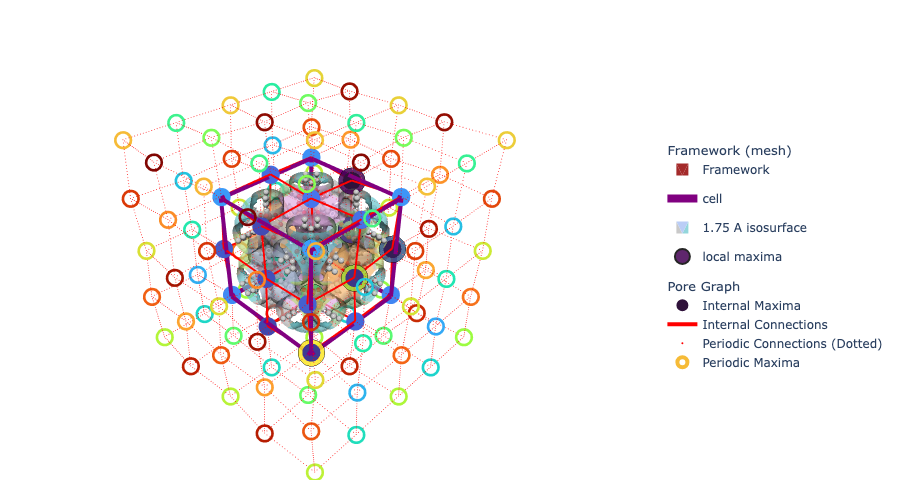

In [10]:
#| fig-cap: "IRMOF-1 pore graph (nodes: pockets, edges: windows) over the framework and the 1.75 Å distance surface."
fig = go.Figure(
    data=[*frame_trace, cell_trace, surface_trace, maxima_trace, *connections_traces]
).update(layout=mgr.white_layout)
fig.show(renderer="png", width=900)

## Where to go next

- [Pocket type detection](pockets_detection.qmd): detect the type of each pocket and add it to the graph.
- [Connections and windows](connections_and_windows.qmd): how the edges are found.